# Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Loading and Preprocessing

In [2]:
# load the csv
pumpkins = pd.read_csv('../data/US-pumpkins.csv')
# pumpkins.head()
# pumpkins.isnull().sum()

# only select all rows of these colums: Package low Price, High Price and Date
columns_to_select = ['Package', 'Low Price', 'High Price', 'Date']
pumpkins = pumpkins.loc[:, columns_to_select]

# average price of a pumpkin in a given month
price = (pumpkins['Low Price'] + pumpkins['High Price']) / 2
# print(price)
month = pd.DatetimeIndex(pumpkins['Date']).month
# print(month)

In [3]:
new_pumpkins = pd.DataFrame({'Month': month, 
                             'Package': pumpkins['Package'], 
                             'Low Price': pumpkins['Low Price'],
                             'High Price': pumpkins['High Price'],
                             'Price': price,
                             })

# selecting only pumpkins with the string 'bushel' in their `Package` column.
pumpkins = pumpkins[pumpkins['Package'].str.contains('bushel', case=True, regex=True)]
print(pumpkins)

new_pumpkins.loc[new_pumpkins['Package'].str.contains('1 1/9'), 'Price'] = price/(1 + 1/9)
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1/2'), 'Price'] = price/(1/2)


                   Package  Low Price  High Price     Date
70    1 1/9 bushel cartons      15.00        15.0  9/24/16
71    1 1/9 bushel cartons      18.00        18.0  9/24/16
72    1 1/9 bushel cartons      18.00        18.0  10/1/16
73    1 1/9 bushel cartons      17.00        17.0  10/1/16
74    1 1/9 bushel cartons      15.00        15.0  10/8/16
...                    ...        ...         ...      ...
1738    1/2 bushel cartons      15.00        15.0  9/30/16
1739    1/2 bushel cartons      13.75        15.0  9/30/16
1740    1/2 bushel cartons      10.75        15.0  9/30/16
1741    1/2 bushel cartons      12.00        12.0  9/30/16
1742    1/2 bushel cartons      12.00        12.0  9/30/16

[415 rows x 4 columns]


# Plotting

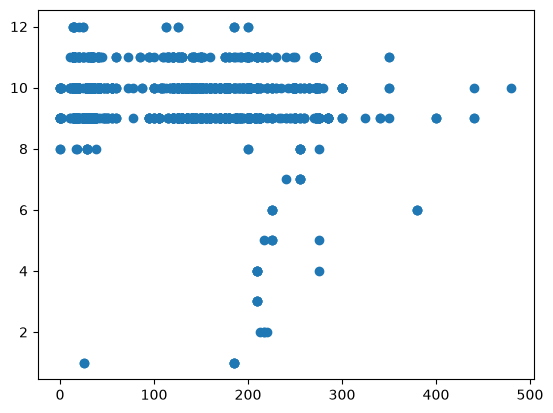

In [4]:
price = new_pumpkins.Price
month = new_pumpkins.Month
plt.scatter(price, month)
plt.show()

Text(0, 0.5, 'Pumpkin Price')

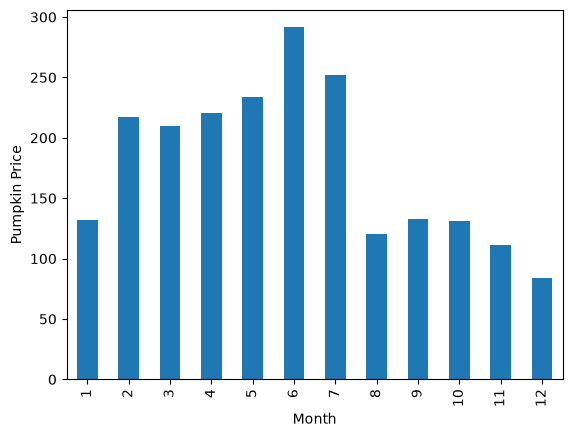

In [5]:
new_pumpkins.groupby(['Month'])['Price'].mean().plot(kind='bar')
plt.ylabel("Pumpkin Price")

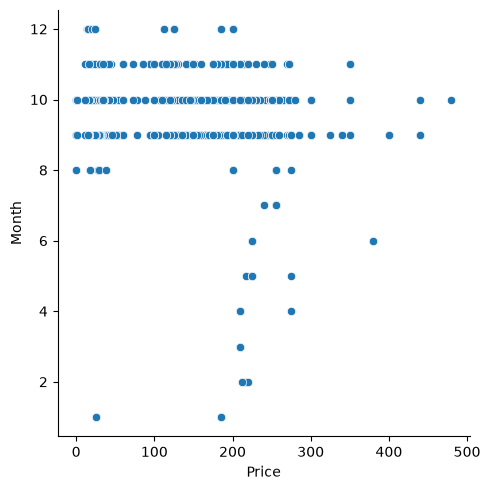

In [6]:
sns.relplot(x="Price", y="Month", data=new_pumpkins)

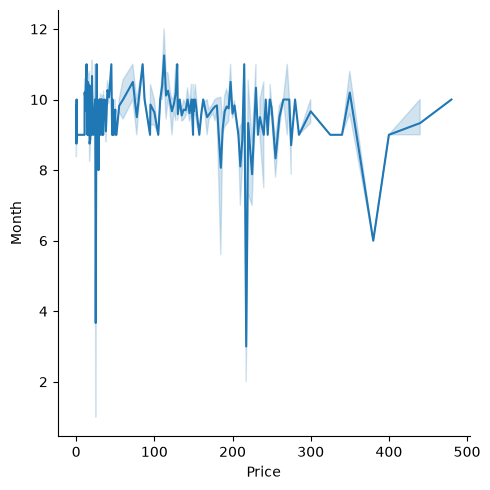

In [7]:
sns.relplot(x="Price", y="Month", kind="line", data=new_pumpkins)

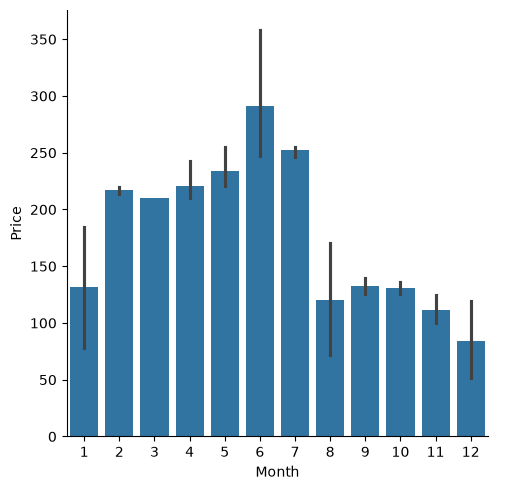

In [8]:
sns.catplot(x="Month", y="Price", data=new_pumpkins, kind="bar")

<Axes: >

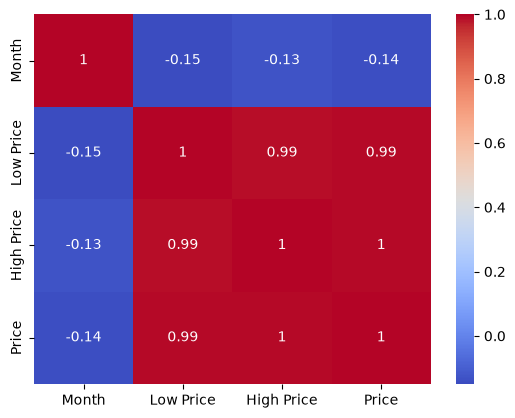

In [9]:
correlations = new_pumpkins[['Month', 'Low Price', 'High Price', 'Price']].corr()
sns.heatmap(correlations, annot=True, cmap="coolwarm")